# 03 - Exploratory Data Analysis

## Financial Transaction Analytics – Money Flows & Fraud Detection

This notebook explores the PaySim financial transactions dataset to identify transaction patterns, monetary flows, and fraud-related characteristics.

### Objectives
- Analyze transaction volumes and monetary flows by transaction type.
- Examine transaction amount distributions.
- Investigate the frequency and monetary impact of fraudulent transactions.
- Compare legitimate and fraudulent transaction patterns.
- Evaluate the behavior and limitations of the `isFlaggedFraud` indicator.
- Produce statistical summaries and visualizations to support business insights.

### Scope
This notebook focuses exclusively on exploratory data analysis (EDA). Data collection and validation are covered in notebooks 01 and 02. Predictive fraud detection models will be developed separately in notebook 04.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
# Define the path to the validated dataset
file_path = Path("../data/processed/paysim_validated.csv")

# Check whether the dataset file exists
file_path.is_file()

True

In [3]:
# Load the validated financial transactions dataset
df = pd.read_csv(file_path)

## 1. Transaction Volumes and Monetary Flows

In [4]:
# Count transactions by type
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [5]:
# Calculate total transaction amount by type
df.groupby("type")["amount"].sum()

type
CASH_IN     2.363674e+11
CASH_OUT    3.944130e+11
DEBIT       2.271992e+08
PAYMENT     2.809337e+10
TRANSFER    4.852920e+11
Name: amount, dtype: float64

In [6]:
# Calculate the average transaction amount by type
df.groupby("type")["amount"].mean().round(2)

type
CASH_IN     168920.24
CASH_OUT    176273.96
DEBIT         5483.67
PAYMENT      13057.60
TRANSFER    910647.01
Name: amount, dtype: float64

## 2. Fraud Frequency and Transaction Characteristics

In [7]:
# Count legitimate and fraudulent transactions
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [8]:
# Calculate the percentage of legitimate and fraudulent transactions
df["isFraud"].value_counts(normalize=True).mul(100).round(4)

isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

In [9]:
# Count fraudulent transactions by transaction type
df[df["isFraud"] == 1]["type"].value_counts()

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

In [10]:
# Calculate fraud rate (%) by transaction type
df.groupby("type")["isFraud"].mean().mul(100).round(4)

type
CASH_IN     0.0000
CASH_OUT    0.1840
DEBIT       0.0000
PAYMENT     0.0000
TRANSFER    0.7688
Name: isFraud, dtype: float64

In [11]:
# Calculate the total amount involved in fraudulent transactions
df.loc[df["isFraud"] == 1, "amount"].sum()

np.float64(12056415427.84)

In [12]:
# Calculate the average amount of fraudulent transactions
df.loc[df["isFraud"] == 1, "amount"].mean().round(2)

np.float64(1467967.3)

In [13]:
# Calculate the median amount of fraudulent transactions
df.loc[df["isFraud"] == 1, "amount"].median().round(2)

np.float64(441423.44)

In [14]:
# Find the maximum amount of a fraudulent transaction
df.loc[df["isFraud"] == 1, "amount"].max()

np.float64(10000000.0)

In [15]:
# Find the minimum amount of a fraudulent transaction
df.loc[df["isFraud"] == 1, "amount"].min()

np.float64(0.0)

In [16]:
# Count fraudulent transactions with zero amount
df.loc[(df["isFraud"] == 1) & (df["amount"] == 0)].shape[0]

16

In [17]:
# Inspect fraudulent transactions with zero amount
df.loc[(df["isFraud"] == 1) & (df["amount"] == 0)]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.0,C1510987794,0.0,0.0,C1696624817,0.00,0.00,1,0
3247298,250,CASH_OUT,0.0,C521393327,0.0,0.0,C480398193,0.00,0.00,1,0
3760289,279,CASH_OUT,0.0,C539112012,0.0,0.0,C1106468520,538547.63,538547.63,1,0
5563714,387,CASH_OUT,0.0,C1294472700,0.0,0.0,C1325541393,7970766.57,7970766.57,1,0
5996408,425,CASH_OUT,0.0,C832555372,0.0,0.0,C1462759334,76759.90,76759.90,1,0
5996410,425,CASH_OUT,0.0,C69493310,0.0,0.0,C719711728,2921531.34,2921531.34,1,0
6168500,554,CASH_OUT,0.0,C10965156,0.0,0.0,C1493336195,230289.66,230289.66,1,0
6205440,586,CASH_OUT,0.0,C1303719003,0.0,0.0,C900608348,1328472.86,1328472.86,1,0
6266414,617,CASH_OUT,0.0,C1971175979,0.0,0.0,C1352345416,0.00,0.00,1,0
6281483,646,CASH_OUT,0.0,C2060908932,0.0,0.0,C1587892888,0.00,0.00,1,0


In [18]:
# Count transactions flagged as potential fraud
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [19]:
# Compare actual fraud labels with fraud flags
pd.crosstab(df["isFraud"], df["isFlaggedFraud"])

isFlaggedFraud,0,1
isFraud,,
0,6354407,0
1,8197,16


In [20]:
# Inspect transactions flagged as potential fraud
df.loc[df["isFlaggedFraud"] == 1]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2736446,212,TRANSFER,4953893.08,C728984460,4953893.08,4953893.08,C639921569,0.0,0.0,1,1
3247297,250,TRANSFER,1343002.08,C1100582606,1343002.08,1343002.08,C1147517658,0.0,0.0,1,1
3760288,279,TRANSFER,536624.41,C1035541766,536624.41,536624.41,C1100697970,0.0,0.0,1,1
5563713,387,TRANSFER,4892193.09,C908544136,4892193.09,4892193.09,C891140444,0.0,0.0,1,1
5996407,425,TRANSFER,10000000.00,C689608084,19585040.37,19585040.37,C1392803603,0.0,0.0,1,1
5996409,425,TRANSFER,9585040.37,C452586515,19585040.37,19585040.37,C1109166882,0.0,0.0,1,1
6168499,554,TRANSFER,3576297.10,C193696150,3576297.10,3576297.10,C484597480,0.0,0.0,1,1
6205439,586,TRANSFER,353874.22,C1684585475,353874.22,353874.22,C1770418982,0.0,0.0,1,1
6266413,617,TRANSFER,2542664.27,C786455622,2542664.27,2542664.27,C661958277,0.0,0.0,1,1
6281482,646,TRANSFER,10000000.00,C19004745,10399045.08,10399045.08,C1806199534,0.0,0.0,1,1


In [21]:
# Calculate minimum and maximum amounts of flagged transactions
df.loc[df["isFlaggedFraud"] == 1, "amount"].agg(["min", "max"])

min      353874.22
max    10000000.00
Name: amount, dtype: float64

In [22]:
# Count transfers exceeding the 200,000 MU threshold
df.loc[(df["type"] == "TRANSFER") & (df["amount"] > 200000)].shape[0]

409110

In [23]:
# Count fraudulent transfers exceeding the 200,000 MU threshold
df.loc[
    (df["type"] == "TRANSFER") &
    (df["amount"] > 200000) &
    (df["isFraud"] == 1)
].shape[0]

2740

In [42]:
# Calculate the detection rate for fraudulent transfers above the threshold
(
    df.loc[
        (df["type"] == "TRANSFER") &
        (df["amount"] > 200000) &
        (df["isFraud"] == 1),
        "isFlaggedFraud"
    ].sum()
    /
    df.loc[
        (df["type"] == "TRANSFER") &
        (df["amount"] > 200000) &
        (df["isFraud"] == 1)
    ].shape[0]
    * 100
)

np.float64(0.583941605839416)

In [25]:
# Compare average and median amounts by fraud status
df.groupby("isFraud")["amount"].agg(["mean", "median"]).round(2)

,mean,median
isFraud,,
0,178197.04,74684.72
1,1467967.30,441423.44


In [26]:
# Calculate average transaction amount by type and fraud status
df.groupby(["type", "isFraud"])["amount"].mean().round(2)

type      isFraud
CASH_IN   0           168920.24
CASH_OUT  0           173917.16
          1          1455102.59
DEBIT     0             5483.67
PAYMENT   0            13057.60
TRANSFER  0           906229.01
          1          1480891.67
Name: amount, dtype: float64

In [27]:
# Calculate median transaction amount by type and fraud status
df.groupby(["type", "isFraud"])["amount"].median().round(2)

type      isFraud
CASH_IN   0          143427.71
CASH_OUT  0          146946.56
          1          435516.90
DEBIT     0            3048.99
PAYMENT   0            9482.19
TRANSFER  0          486521.91
          1          445705.76
Name: amount, dtype: float64

In [28]:
# Calculate amount quartiles for fraudulent transactions
df.loc[df["isFraud"] == 1, "amount"].quantile([0.25, 0.50, 0.75]).round(2)

0.25     127091.33
0.50     441423.44
0.75    1517771.48
Name: amount, dtype: float64

In [29]:
# Calculate amount quartiles for legitimate transactions
df.loc[df["isFraud"] == 0, "amount"].quantile([0.25, 0.50, 0.75]).round(2)

0.25     13368.40
0.50     74684.72
0.75    208364.76
Name: amount, dtype: float64

In [30]:
# Compare amount quartiles by fraud status
df.groupby("isFraud")["amount"].quantile([0.25, 0.50, 0.75]).round(2)

isFraud      
0        0.25      13368.40
         0.50      74684.72
         0.75     208364.76
1        0.25     127091.33
         0.50     441423.44
         0.75    1517771.48
Name: amount, dtype: float64

## 3. Data Visualization

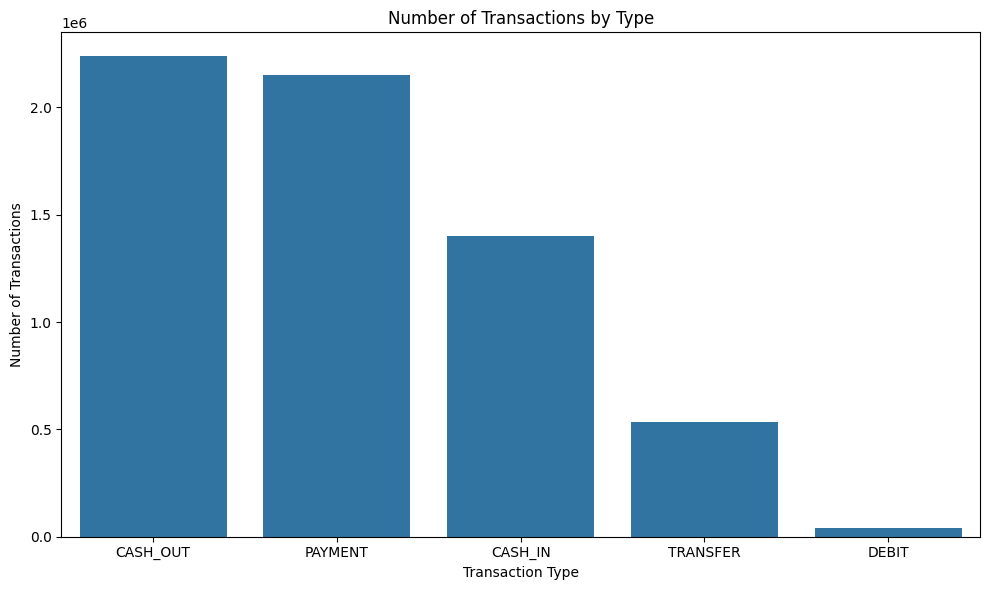

In [31]:
# Visualize transaction counts by type
transaction_counts = df["type"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=transaction_counts.index, y=transaction_counts.values)

plt.title("Number of Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

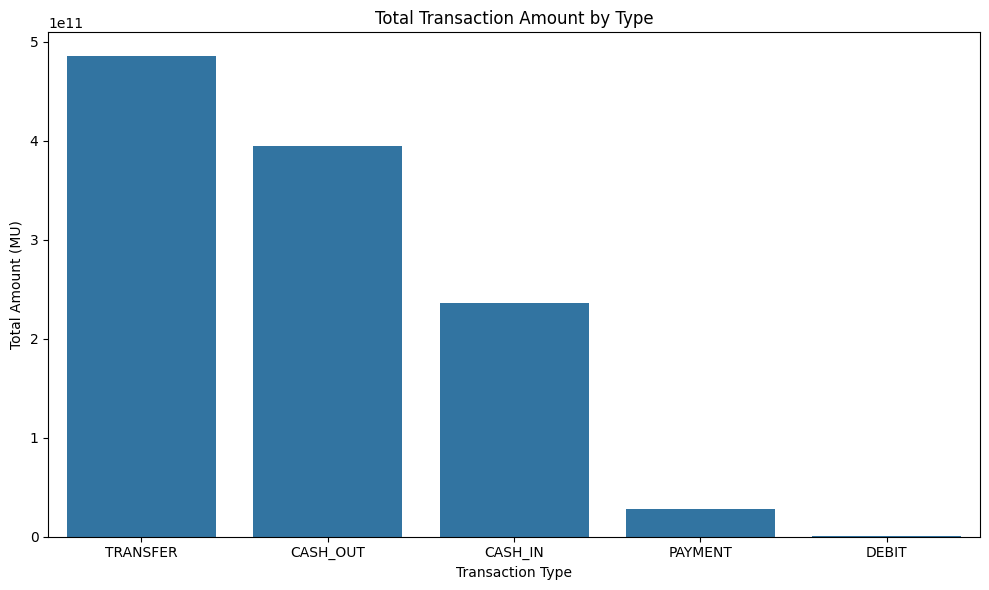

In [32]:
# Visualize total transaction amount by type
total_amounts = df.groupby("type")["amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=total_amounts.index, y=total_amounts.values)

plt.title("Total Transaction Amount by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount (MU)")
plt.tight_layout()
plt.show()

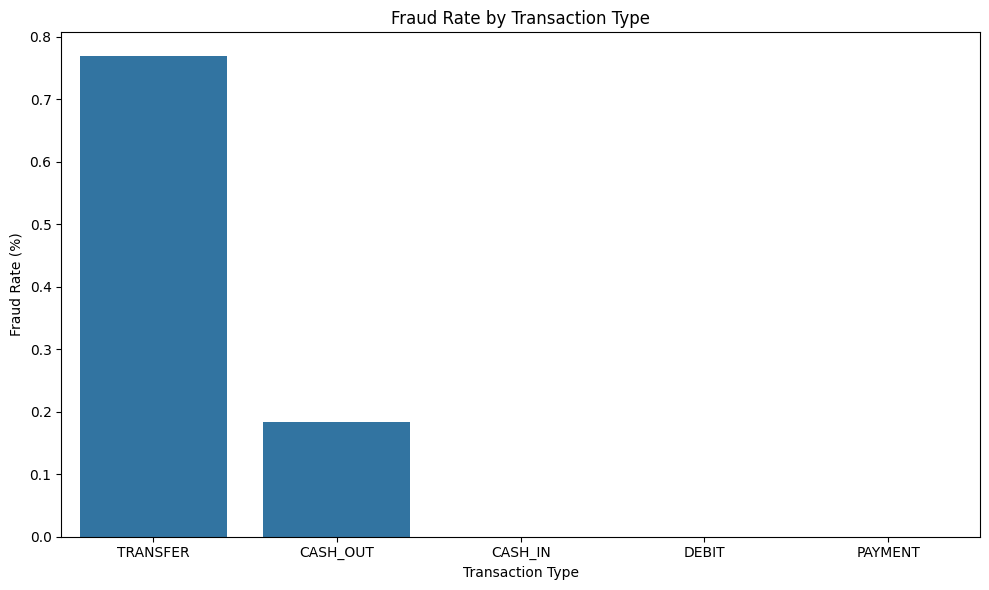

In [33]:
# Visualize fraud rate by transaction type
fraud_rates = df.groupby("type")["isFraud"].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=fraud_rates.index, y=fraud_rates.values)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()


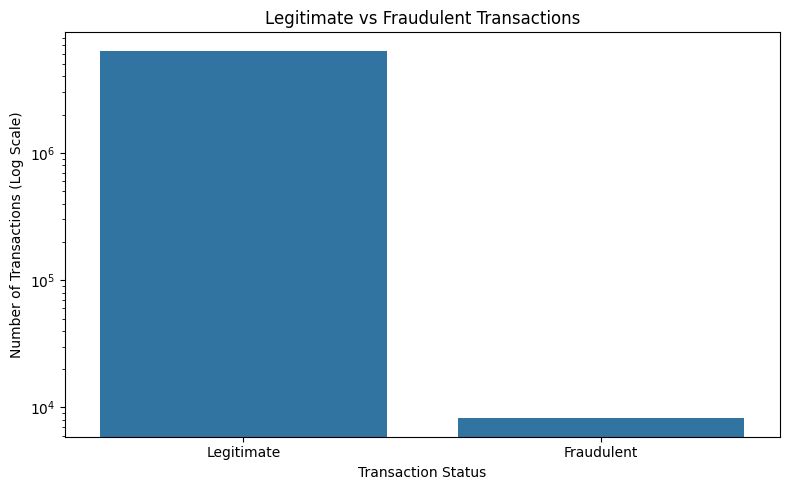

In [34]:
# Visualize legitimate and fraudulent transaction counts using a logarithmic scale
fraud_counts = df["isFraud"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Legitimate", "Fraudulent"],
    y=fraud_counts.values
)

plt.yscale("log")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions (Log Scale)")

plt.tight_layout()
plt.show()

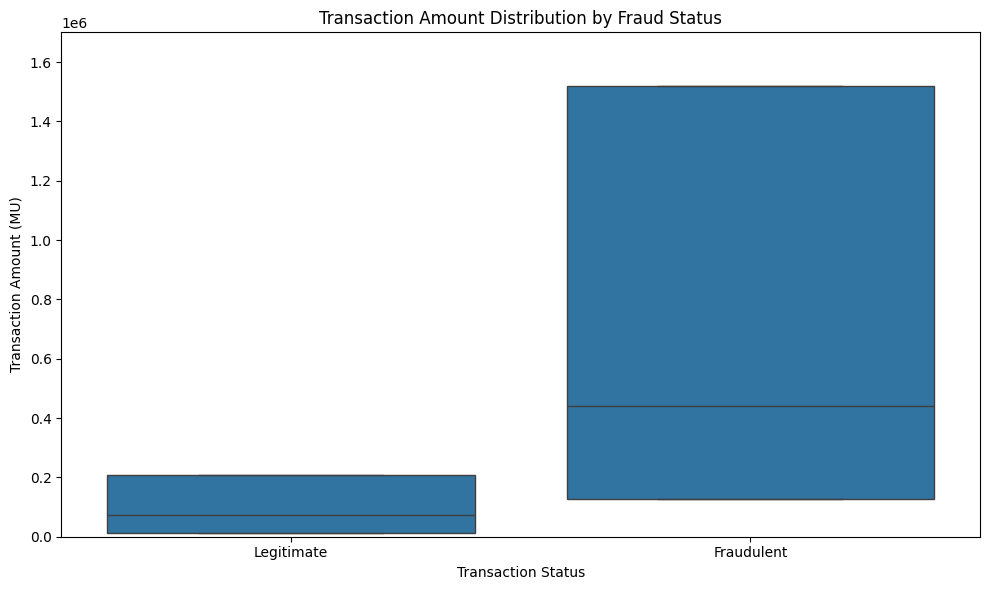

In [35]:
# Compare transaction amount distributions by fraud status
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount",
    showfliers=False,
    whis=0
)

plt.ylim(0, 1700000)

plt.title("Transaction Amount Distribution by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Transaction Amount (MU)")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.tight_layout()
plt.show()

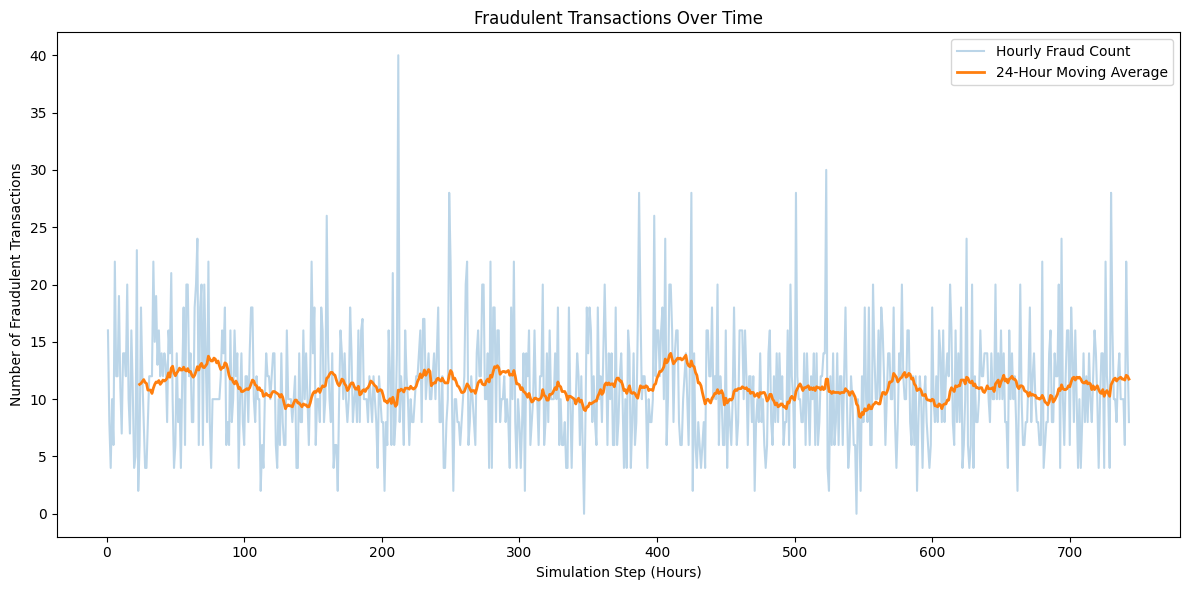

In [36]:
# Analyze fraudulent transactions over time
fraud_by_step = (
    df.loc[df["isFraud"] == 1]
    .groupby("step")
    .size()
    .reindex(range(1, 744), fill_value=0)
)

# Calculate the 24-hour moving average
fraud_moving_avg = fraud_by_step.rolling(window=24).mean()

plt.figure(figsize=(12, 6))

plt.plot(
    fraud_by_step.index,
    fraud_by_step.values,
    alpha=0.3,
    label="Hourly Fraud Count"
)

plt.plot(
    fraud_moving_avg.index,
    fraud_moving_avg.values,
    linewidth=2,
    label="24-Hour Moving Average"
)

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Simulation Step (Hours)")
plt.ylabel("Number of Fraudulent Transactions")
plt.legend()

plt.tight_layout()
plt.show()

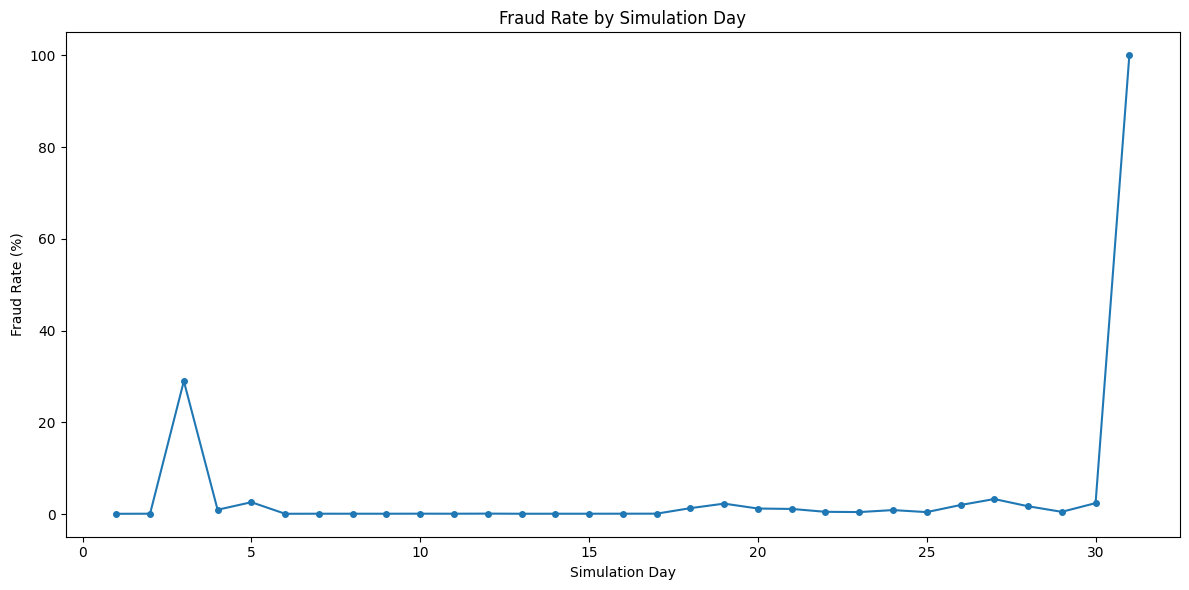

In [37]:
# Calculate fraud rates for non-overlapping 24-hour periods
daily_fraud = (
    df.assign(day=(df["step"] - 1) // 24 + 1)
    .groupby("day")["isFraud"]
    .agg(["sum", "count"])
)

# Calculate the percentage of fraudulent transactions per day
daily_fraud["fraud_rate"] = (
    daily_fraud["sum"] / daily_fraud["count"] * 100
)

# Visualize the daily fraud rate
plt.figure(figsize=(12, 6))

plt.plot(
    daily_fraud.index,
    daily_fraud["fraud_rate"],
    marker="o",
    markersize=4
)

plt.title("Fraud Rate by Simulation Day")
plt.xlabel("Simulation Day")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [38]:
# Inspect transaction volumes and fraud rates by simulation day
daily_fraud[["count", "sum", "fraud_rate"]].round(4)

,count,sum,fraud_rate
day,,,
1,574255,271,0.0472
2,455238,309,0.0679
3,1070,310,28.9720
4,28240,262,0.9278
5,9789,252,2.5743
6,441005,228,0.0517
7,420583,272,0.0647
8,449637,278,0.0618
9,417919,255,0.0610


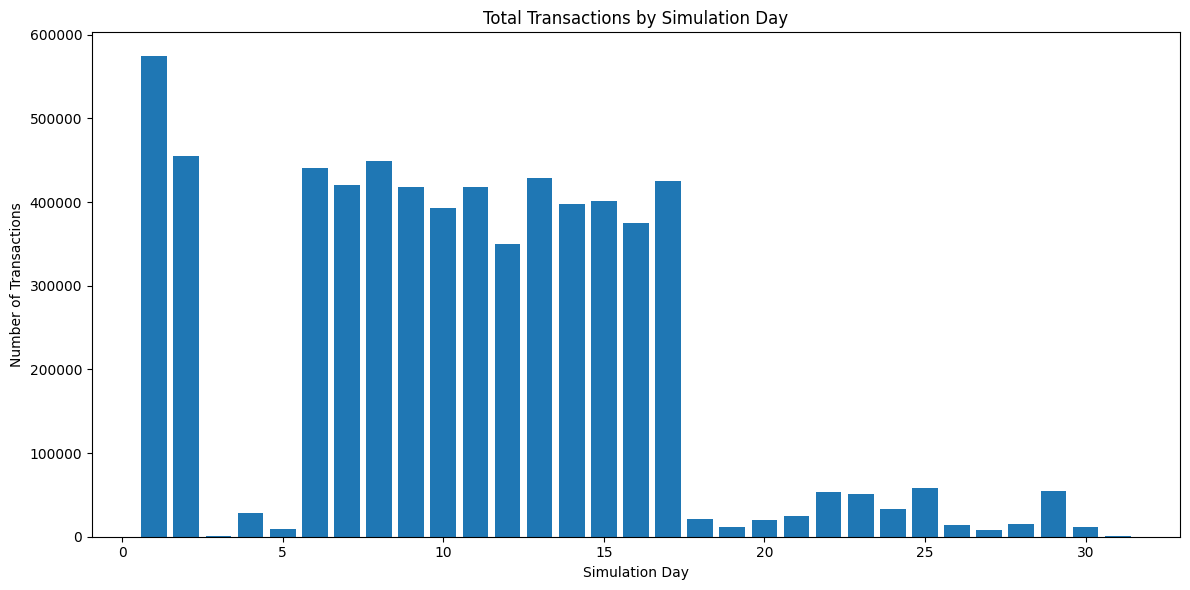

In [39]:
# Visualize daily transaction volumes
plt.figure(figsize=(12, 6))

plt.bar(
    daily_fraud.index,
    daily_fraud["count"]
)

plt.title("Total Transactions by Simulation Day")
plt.xlabel("Simulation Day")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### Temporal Analysis – Key Findings

The PaySim dataset exhibits substantial variations in transaction volume across simulation days.

While the daily number of fraudulent transactions remains relatively stable, the total number of transactions changes dramatically, particularly after simulation day 17.

As a result, daily fraud rates can become unusually high when transaction volumes are very low. For example, simulation day 31 contains 272 transactions, all classified as fraudulent, resulting in a 100% fraud rate.

These patterns highlight an important limitation of the synthetic dataset: temporal fraud rates must be interpreted alongside transaction volumes.

Consequently, high fraud percentages should not automatically be interpreted as evidence of increasing fraudulent activity.

In [40]:
# Calculate total transaction amount by fraud status
amount_by_fraud = df.groupby("isFraud")["amount"].sum()

# Calculate the percentage of monetary volume associated with fraud
fraud_amount_percentage = (
    amount_by_fraud.loc[1] / amount_by_fraud.sum() * 100
)

print(f"Total transaction amount: {amount_by_fraud.sum():,.2f} MU")
print(f"Fraudulent transaction amount: {amount_by_fraud.loc[1]:,.2f} MU")
print(f"Fraudulent monetary volume: {fraud_amount_percentage:.4f}%")

Total transaction amount: 1,144,392,944,759.77 MU
Fraudulent transaction amount: 12,056,415,427.84 MU
Fraudulent monetary volume: 1.0535%


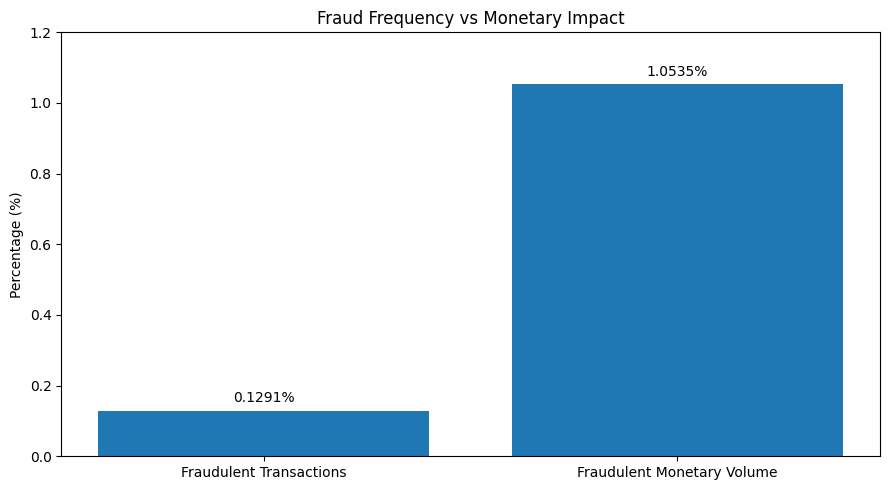

In [41]:
# Compare fraud frequency and monetary impact
fraud_transaction_percentage = df["isFraud"].mean() * 100

metrics = [
    "Fraudulent Transactions",
    "Fraudulent Monetary Volume"
]

percentages = [
    fraud_transaction_percentage,
    fraud_amount_percentage
]

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics, percentages)

plt.bar_label(bars, fmt="%.4f%%", padding=4)

plt.title("Fraud Frequency vs Monetary Impact")
plt.ylabel("Percentage (%)")
plt.ylim(0, 1.2)

plt.tight_layout()
plt.show()

### Financial Impact – Key Findings

Fraudulent transactions account for approximately 0.1291% of all transactions but represent 1.0535% of the total monetary volume.

This indicates that fraudulent transactions tend to involve substantially larger amounts than legitimate transactions.

The monetary share of fraud is approximately 8.2 times its share of transaction counts.

These figures represent transaction amounts associated with fraud, not necessarily actual financial losses.